<a href="https://colab.research.google.com/github/gchekwemoi/OOP-python-assignment/blob/main/project5_taxi_planner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Portable setup for Anaconda/Jupyter and Google Colab
from pathlib import Path
import os
import sys
import subprocess

repo = Path.cwd().resolve()
if not (repo / "src").is_dir():
    colab_repo = Path("/content/OOP-python-assignment")
    if colab_repo.is_dir():
        repo = colab_repo
    elif "google.colab" in sys.modules or os.environ.get("COLAB_RELEASE_TAG"):
        subprocess.run(
            ["git", "clone", "https://github.com/gchekwemoi/OOP-python-assignment.git",
             str(colab_repo)], check=True
        )
        repo = colab_repo
    else:
        raise FileNotFoundError(
            "Open Jupyter from the OOP-python-assignment repository folder, "
            "which must contain the src/ and tests/ directories."
        )
os.chdir(repo)
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Project directory:", repo)

# Check the project's automated tests
subprocess.run([sys.executable, "-m", "pytest", "tests/test_taxi.py", "-v"], check=True)


Cloning into 'OOP-python-assignment'...
remote: Enumerating objects: 117, done.
remote: Counting objects: 100% (117/117), done.
remote: Compressing objects: 100% (108/108), done.
remote: Total 117 (delta 50), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (117/117), 1003.82 KiB | 6.78 MiB/s, done.
Resolving deltas: 100% (50/50), done.
/content/OOP-python-assignment
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/OOP-python-assignment
plugins: anyio-4.15.1, platformdirs-4.12.2, langsmith-0.14.2, typeguard-4.6.0
collected 10 items                                                             

tests/test_taxi.py::test_route_daily_revenue PASSED                      [ 10%]
tests/test_taxi.py::test_route_total_revenue PASSED                      [ 20%]
tests/test_taxi.py::test_route_statistics PASSED                   

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.taxi_route import Route
from src.taxi_forecasting import (
    MovingAverageForecaster,
    ExponentialSmoothingForecaster,
    LinearTrendForecaster
)

# Create the three taxi route objects
ntinda = Route(
    "Kampala-Ntinda",
    [35, 40, 42, 50, 55, 60, 48, 52, 47, 45],
    2000
)

entebbe = Route(
    "Kampala-Entebbe",
    [60, 58, 65, 70, 72, 80, 75, 68, 66, 64],
    5000
)

mukono = Route(
    "Kampala-Mukono",
    [45, 47, 50, 49, 55, 62, 58, 53, 51, 50],
    3000
)

routes = [ntinda, entebbe, mukono]

# Calculate descriptive statistics and revenue
summary_rows = []

for route in routes:
    stats = route.summary_statistics()

    summary_rows.append({
        "Route": route.name,
        "Fare (UGX)": route.fare,
        "Mean Passengers": stats["mean"],
        "Variance": stats["variance"],
        "Standard Deviation": stats["standard_deviation"],
        "Total Revenue (UGX)": route.total_revenue()
    })

route_summary = pd.DataFrame(summary_rows)

print("TAXI ROUTE REVENUE ANALYSIS")
display(route_summary.round(2))

# Display daily passenger counts and revenue
daily_rows = []

for route in routes:
    for day, passengers in enumerate(route.passengers, start=1):
        daily_rows.append({
            "Route": route.name,
            "Day": day,
            "Passengers": int(passengers),
            "Fare (UGX)": route.fare,
            "Daily Revenue (UGX)": passengers * route.fare
        })

daily_data = pd.DataFrame(daily_rows)

print("\nDAILY PASSENGER AND REVENUE DATA")
display(daily_data)


TAXI ROUTE REVENUE ANALYSIS


,Route,Fare (UGX),Mean Passengers,Variance,Standard Deviation,Total Revenue (UGX)
0,Kampala-Ntinda,2000.0,47.4,54.27,7.37,948000.0
1,Kampala-Entebbe,5000.0,67.8,45.07,6.71,3390000.0
2,Kampala-Mukono,3000.0,52.0,26.44,5.14,1560000.0



DAILY PASSENGER AND REVENUE DATA


,Route,Day,Passengers,Fare (UGX),Daily Revenue (UGX)
0,Kampala-Ntinda,1,35,2000.0,70000.0
1,Kampala-Ntinda,2,40,2000.0,80000.0
2,Kampala-Ntinda,3,42,2000.0,84000.0
3,Kampala-Ntinda,4,50,2000.0,100000.0
4,Kampala-Ntinda,5,55,2000.0,110000.0
5,Kampala-Ntinda,6,60,2000.0,120000.0
6,Kampala-Ntinda,7,48,2000.0,96000.0
7,Kampala-Ntinda,8,52,2000.0,104000.0
8,Kampala-Ntinda,9,47,2000.0,94000.0
9,Kampala-Ntinda,10,45,2000.0,90000.0


In [3]:

# STEP 6: TAXI SUPPLY-DEMAND EQUILIBRIUM

import numpy as np
import pandas as pd
from scipy.linalg import solve

# Equations:
# Q + 0.02P = 120
# Q - 0.03P = 10

A = np.array([
    [1, 0.02],
    [1, -0.03]
], dtype=float)

b = np.array([120, 10], dtype=float)

# Solve for equilibrium quantity and fare
equilibrium_quantity, equilibrium_fare = solve(A, b)

current_fare = 2000

# Demand and supply at current fare
current_demand = 120 - 0.02 * current_fare
current_supply = 10 + 0.03 * current_fare

# Display results
equilibrium_results = pd.DataFrame({
    "Measure": [
        "Equilibrium fare (UGX)",
        "Equilibrium passengers per trip-hour",
        "Current fare (UGX)",
        "Demand at current fare",
        "Supply at current fare",
        "Excess demand"
    ],
    "Value": [
        equilibrium_fare,
        equilibrium_quantity,
        current_fare,
        current_demand,
        current_supply,
        current_demand - current_supply
    ]
})

print("KAMPALA–NTINDA TAXI FARE EQUILIBRIUM")
display(equilibrium_results.round(2))

if current_fare < equilibrium_fare:
    print("The current fare is BELOW equilibrium.")
elif current_fare > equilibrium_fare:
    print("The current fare is ABOVE equilibrium.")
else:
    print("The current fare is AT equilibrium.")


KAMPALA–NTINDA TAXI FARE EQUILIBRIUM


,Measure,Value
0,Equilibrium fare (UGX),2200.0
1,Equilibrium passengers per trip-hour,76.0
2,Current fare (UGX),2000.0
3,Demand at current fare,80.0
4,Supply at current fare,70.0
5,Excess demand,10.0


The current fare is BELOW equilibrium.


In [4]:

import numpy as np
import pandas as pd

from src.taxi_forecasting import (
    MovingAverageForecaster,
    ExponentialSmoothingForecaster,
    LinearTrendForecaster
)

# Candidate alpha values for exponential smoothing
alpha_values = np.arange(0.1, 1.01, 0.1)

comparison_rows = []
best_models = {}

for route in routes:
    actual = route.passengers
    errors_by_model = {}

    # Walk-forward testing: predict Days 4-10
    for model_name in ["Moving Average", "Linear Trend"]:
        predictions = []
        actual_values = []

        for day in range(3, len(actual)):
            training_data = actual[:day]

            if model_name == "Moving Average":
                model = MovingAverageForecaster()
            else:
                model = LinearTrendForecaster()

            model.fit(training_data)
            predictions.append(model.predict())
            actual_values.append(actual[day])

        mae = np.mean(
            np.abs(np.array(actual_values) - np.array(predictions))
        )

        errors_by_model[model_name] = float(mae)

    # Tune alpha for exponential smoothing
    best_alpha = None
    best_smoothing_mae = float("inf")

    for alpha in alpha_values:
        predictions = []
        actual_values = []

        for day in range(3, len(actual)):
            model = ExponentialSmoothingForecaster(
                alpha=float(alpha)
            )

            model.fit(actual[:day])

            predictions.append(model.predict())
            actual_values.append(actual[day])

        mae = np.mean(
            np.abs(np.array(actual_values) - np.array(predictions))
        )

        if mae < best_smoothing_mae:
            best_smoothing_mae = float(mae)
            best_alpha = float(alpha)

    errors_by_model["Exponential Smoothing"] = best_smoothing_mae

    # Select best model
    selected_model = min(errors_by_model, key=errors_by_model.get)

    best_models[route.name] = {
        "Model": selected_model,
        "Alpha": best_alpha if selected_model == "Exponential Smoothing" else None,
        "MAE": errors_by_model[selected_model]
    }

    # Store comparison results
    for model_name, mae in errors_by_model.items():
        comparison_rows.append({
            "Route": route.name,
            "Forecast Model": model_name,
            "MAE": mae,
            "Best Alpha": best_alpha if model_name == "Exponential Smoothing" else np.nan
        })

comparison_df = pd.DataFrame(comparison_rows)

print("WALK-FORWARD FORECASTING MODEL COMPARISON")
display(comparison_df.round(3))

print("\nBEST FORECASTING MODEL FOR EACH ROUTE")
display(pd.DataFrame.from_dict(best_models, orient="index"))


WALK-FORWARD FORECASTING MODEL COMPARISON


,Route,Forecast Model,MAE,Best Alpha
0,Kampala-Ntinda,Moving Average,7.524,NaN
1,Kampala-Ntinda,Linear Trend,7.873,NaN
2,Kampala-Ntinda,Exponential Smoothing,5.857,1.0
3,Kampala-Entebbe,Moving Average,7.190,NaN
4,Kampala-Entebbe,Linear Trend,7.711,NaN
5,Kampala-Entebbe,Exponential Smoothing,4.429,1.0
6,Kampala-Mukono,Moving Average,5.333,NaN
7,Kampala-Mukono,Linear Trend,6.391,NaN
8,Kampala-Mukono,Exponential Smoothing,3.714,1.0



BEST FORECASTING MODEL FOR EACH ROUTE


,Model,Alpha,MAE
Kampala-Ntinda,Exponential Smoothing,1.0,5.857143
Kampala-Entebbe,Exponential Smoothing,1.0,4.428571
Kampala-Mukono,Exponential Smoothing,1.0,3.714286


In [5]:

import numpy as np
import pandas as pd
import math

from src.taxi_forecasting import (
    MovingAverageForecaster,
    ExponentialSmoothingForecaster,
    LinearTrendForecaster
)

fleet_rows = []
day11_forecasts = {}

# Each taxi carries 14 passengers per trip
SEATS_PER_TAXI = 14

# Each taxi makes 8 one-way trips daily
TRIPS_PER_DAY = 8

# Add a 15% planning buffer
BUFFER = 0.15

capacity_per_taxi = SEATS_PER_TAXI * TRIPS_PER_DAY

for route in routes:

    # Identify the best forecasting model
    selection = best_models[route.name]
    model_name = selection["Model"]

    if model_name == "Moving Average":
        model = MovingAverageForecaster()

    elif model_name == "Exponential Smoothing":
        model = ExponentialSmoothingForecaster(
            alpha=selection["Alpha"]
        )

    else:
        model = LinearTrendForecaster()

    # Train using all 10 available days
    model.fit(route.passengers)

    # Predict Day 11 passengers
    predicted_passengers = max(0, model.predict())

    # Calculate expected revenue
    predicted_revenue = predicted_passengers * route.fare

    # Apply the capacity buffer before rounding up
    required_capacity = predicted_passengers * (1 + BUFFER)

    vehicles_needed = math.ceil(
        required_capacity / capacity_per_taxi
    )

    day11_forecasts[route.name] = predicted_passengers

    fleet_rows.append({
        "Route": route.name,
        "Best Model": model_name,
        "Day 11 Passengers": predicted_passengers,
        "Fare (UGX)": route.fare,
        "Expected Revenue (UGX)": predicted_revenue,
        "Daily Capacity per Taxi": capacity_per_taxi,
        "Vehicles Required": vehicles_needed
    })

fleet_summary = pd.DataFrame(fleet_rows)

print("DAY 11 PASSENGER, REVENUE AND FLEET FORECAST")
display(fleet_summary.round(2))

print("\nTotal taxis required:",
      fleet_summary["Vehicles Required"].sum())


DAY 11 PASSENGER, REVENUE AND FLEET FORECAST


,Route,Best Model,Day 11 Passengers,Fare (UGX),Expected Revenue (UGX),Daily Capacity per Taxi,Vehicles Required
0,Kampala-Ntinda,Exponential Smoothing,45.0,2000.0,90000.0,112,1
1,Kampala-Entebbe,Exponential Smoothing,64.0,5000.0,320000.0,112,1
2,Kampala-Mukono,Exponential Smoothing,50.0,3000.0,150000.0,112,1



Total taxis required: 3


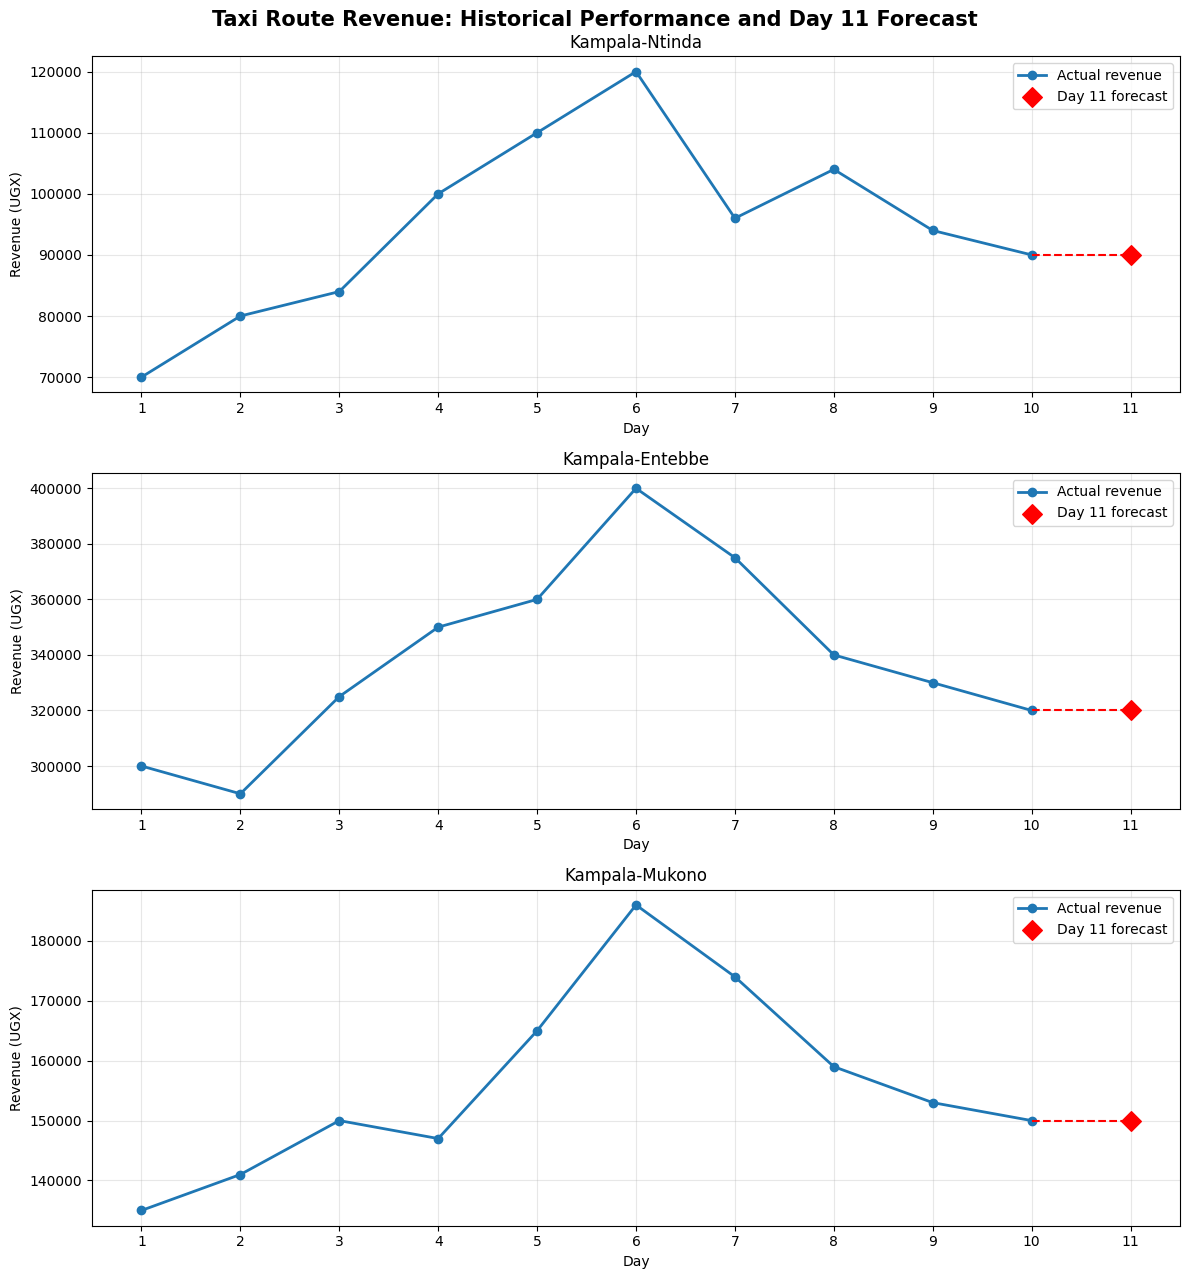

In [6]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 1, figsize=(12, 13))

for ax, route in zip(axes, routes):

    days = np.arange(1, 11)
    actual_revenue = route.daily_revenue()

    forecast_revenue = (
        day11_forecasts[route.name] * route.fare
    )

    # Plot actual revenue for Days 1-10
    ax.plot(
        days,
        actual_revenue,
        marker="o",
        linewidth=2,
        label="Actual revenue"
    )

    # Plot the forecast for Day 11
    ax.scatter(
        [11],
        [forecast_revenue],
        color="red",
        s=100,
        marker="D",
        label="Day 11 forecast",
        zorder=5
    )

    # Connect Day 10 actual revenue to forecast
    ax.plot(
        [10, 11],
        [actual_revenue[-1], forecast_revenue],
        linestyle="--",
        color="red"
    )

    ax.set_title(route.name)
    ax.set_xlabel("Day")
    ax.set_ylabel("Revenue (UGX)")
    ax.set_xticks(range(1, 12))
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Taxi Route Revenue: Historical Performance and Day 11 Forecast",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


60-DAY SEASONAL FORECAST COMPARISON


,Model,MAE (passengers)
0,3-Day Moving Average,9.86
1,Seasonal Naive,2.91



Best model: Seasonal Naive


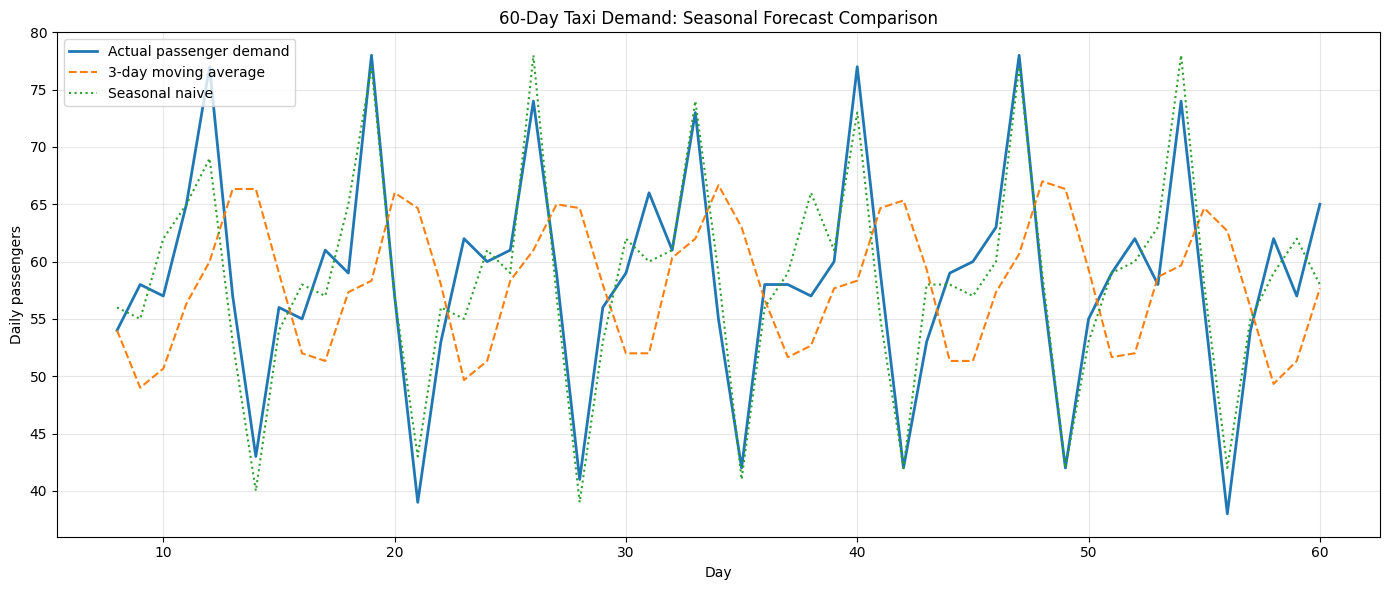

In [8]:

# PROJECT 5 EXTENSION: 60-DAY SEASONAL FORECASTING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixed random seed for reproducibility
rng = np.random.default_rng(42)

days = np.arange(1, 61)
weekdays = np.arange(60) % 7

# Monday=0, Friday=4, Sunday=6
# Construct a clear weekly demand pattern
weekday_effect = np.array([0, 3, 5, 7, 20, 2, -15])

# Simulate passenger counts with random variation
base_demand = 55
noise = rng.normal(0, 3, size=60)

passengers = np.maximum(
    0,
    np.rint(
        base_demand + weekday_effect[weekdays] + noise
    )
).astype(int)

# Evaluate forecasts from Day 8 to Day 60
actual = []
moving_average_predictions = []
seasonal_predictions = []

for day in range(7, len(passengers)):
    actual.append(passengers[day])

    moving_average_predictions.append(
        np.mean(passengers[day-3:day])
    )

    # Same weekday in the previous week
    seasonal_predictions.append(passengers[day-7])

actual = np.array(actual)

moving_average_predictions = np.array(
    moving_average_predictions
)

seasonal_predictions = np.array(seasonal_predictions)

# Calculate MAE
mae_moving = np.mean(
    np.abs(actual - moving_average_predictions)
)

mae_seasonal = np.mean(
    np.abs(actual - seasonal_predictions)
)

comparison = pd.DataFrame({
    "Model": [
        "3-Day Moving Average",
        "Seasonal Naive"
    ],
    "MAE (passengers)": [
        mae_moving,
        mae_seasonal
    ]
})

print("60-DAY SEASONAL FORECAST COMPARISON")
display(comparison.round(2))

print("\nBest model:",
      comparison.loc[
          comparison["MAE (passengers)"].idxmin(),
          "Model"
      ])

# Visualise actual passenger demand and predictions
plt.figure(figsize=(14, 6))

plt.plot(
    days[7:],
    actual,
    label="Actual passenger demand",
    linewidth=2
)

plt.plot(
    days[7:],
    moving_average_predictions,
    label="3-day moving average",
    linestyle="--"
)

plt.plot(
    days[7:],
    seasonal_predictions,
    label="Seasonal naive",
    linestyle=":"
)

plt.xlabel("Day")
plt.ylabel("Daily passengers")
plt.title("60-Day Taxi Demand: Seasonal Forecast Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Findings & Limitations

This project developed a Python-based Taxi Route Revenue, Pricing and Fleet Planner for three Kampala routes: Ntinda, Entebbe and Mukono. Object-oriented programming was used to represent taxi routes, calculate passenger statistics and compare demand forecasting models.

The analysis used ten days of passenger counts and the fares provided in the assignment. The supply-demand model estimated an equilibrium fare of UGX 2,200 for the Kampala–Ntinda route, compared with the current fare of UGX 2,000. At the current fare, the illustrative equations indicate excess demand of ten passengers per trip-hour.

Three forecasting methods were evaluated: three-day moving average, exponential smoothing and linear trend. Walk-forward backtesting over Days 4–10 was used to calculate the Mean Absolute Error (MAE), while grid search identified the preferred smoothing parameter. The model with the lowest MAE was selected to forecast Day 11 passenger demand and revenue for each route.

Fleet requirements were estimated assuming each taxi carries a maximum of 14 passengers per trip and makes eight one-way trips daily, with an additional 15% capacity buffer. The 60-day extension introduced weekly demand patterns, including higher passenger numbers on Fridays and lower numbers on Sundays, to compare seasonal-naïve forecasting with moving averages.

**Limitations:** The analysis relies on illustrative passenger data and simplified demand equations rather than actual taxi association records. It assumes fixed fares, full vehicle capacity and eight trips daily. Actual fleet requirements may be higher because of congestion, peak-hour demand, vehicle breakdowns and uneven passenger arrivals. The short historical dataset also limits forecasting reliability. Consequently, the findings demonstrate useful planning methods rather than definitive operational recommendations.